# Lab 7

In [20]:
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.io import wavfile
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
np.set_printoptions(precision=3, suppress=True)

RAIZ = Path.cwd()
DIR_FIGS = RAIZ / "figs"
DIR_FEATURES = RAIZ / "features"
DIR_FIGS.mkdir(exist_ok=True)
DIR_FEATURES.mkdir(exist_ok=True)

SEMILLA = 42
rng_global = np.random.default_rng(SEMILLA)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})


def guardar_fig(nombre):
    ruta = DIR_FIGS / f"{nombre}.png"
    plt.savefig(ruta, bbox_inches="tight")
    print(f"Figura guardada en: {ruta}")
    return ruta


import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import torchaudio
from torchaudio.datasets import SPEECHCOMMANDS

torch.manual_seed(SEMILLA)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMILLA)

print("Versiones:")
print(f"  numpy      : {np.__version__}")
print(f"  scikit-learn: {__import__('sklearn').__version__}")
print(f"  torch      : {torch.__version__}")
print(f"  torchaudio : {torchaudio.__version__}")
print(f"  CUDA disponible: {torch.cuda.is_available()}")

Versiones:
  numpy      : 2.4.6
  scikit-learn: 1.9.0
  torch      : 2.13.0+cu130
  torchaudio : 2.11.0+cu130
  CUDA disponible: True


In [21]:
def generar_centroides_separados(n_centers, dimensiones, limite, distancia_minima, rng,
                                 max_intentos=200000):
    """Genera `n_centers` posiciones aleatorias con separacion minima entre ellas.

    Parametros
    ----------
    n_centers : int
        Cantidad de centroides a generar.
    dimensiones : int
        Dimension del espacio (2 para el Punto 1, 3 para el Punto 2).
    limite : float
        Los centroides se generan en el hipercubo [-limite, limite]^dimensiones.
    distancia_minima : float
        Distancia euclidiana minima exigida entre cualquier par de centroides.
    rng : np.random.Generator
        Generador de numeros aleatorios.
    """
    centros = []
    intentos = 0
    while len(centros) < n_centers and intentos < max_intentos:
        candidato = rng.uniform(-limite, limite, size=dimensiones)
        if not centros or all(
            np.linalg.norm(candidato - c) >= distancia_minima for c in centros
        ):
            centros.append(candidato)
        intentos += 1

    if len(centros) != n_centers:
        raise RuntimeError(
            "No fue posible ubicar todos los centroides con la separacion "
            "solicitada. Reduzca `distancia_minima` o `n_centers`."
        )
    return np.asarray(centros)


def generar_dataset(dimensiones, rng, limite=50.0, distancia_minima=8.0,
                    std_min=0.55, std_max=1.80, puntos_min=70, puntos_max=220):
    n_centers = int(rng.integers(1, 21))

    centros = generar_centroides_separados(
        n_centers=n_centers,
        dimensiones=dimensiones,
        limite=limite,
        distancia_minima=distancia_minima,
        rng=rng,
    )
    std = rng.uniform(std_min, std_max, size=n_centers)
    n_puntos = rng.integers(puntos_min, puntos_max + 1, size=n_centers)

    partes_X, partes_y = [], []
    for i, (centro, sigma, cantidad) in enumerate(zip(centros, std, n_puntos)):
        puntos = rng.normal(loc=centro, scale=sigma, size=(int(cantidad), dimensiones))
        partes_X.append(puntos)
        partes_y.append(np.full(int(cantidad), i, dtype=int))

    X = np.vstack(partes_X)
    y_verdadero = np.concatenate(partes_y)

    orden = rng.permutation(len(X))
    return X[orden], y_verdadero[orden], centros, std, n_puntos


def cinco_puntos_mas_cercanos(X, etiquetas, centroides, n=5):
    distancias = cdist(X, centroides)
    resultado = {}
    for i in range(len(centroides)):
        indices_cluster = np.where(etiquetas == i)[0]
        if len(indices_cluster) == 0:
            resultado[i] = np.array([], dtype=int)
            continue
        dist_cluster = distancias[indices_cluster, i]
        orden = np.argsort(dist_cluster)[: min(n, len(indices_cluster))]
        resultado[i] = indices_cluster[orden]
    return resultado, distancias


def resumen_por_cluster(etiquetas, centroides):
    return np.bincount(etiquetas, minlength=len(centroides))

# K-Means sobre datos generados aleatoriamente en 2D
- Modificar el generador de dataset aleatorio, para que este pueda generar centroides en cantidades entre 1 y 20, y considerando una importante distancia entre ellos con la finalidad de permitir la verificación visual una vez se realice el entrenamiento del modelo.
- Establecer aleatoriamente las posiciones de los centroides.
- Establecer aleatoriamente las distancias de los puntos generados con respecto a los centroides.
- Establecer aleatoriamente el numero de puntos por centroide.
- Aplicar KMeans y visualizar la ubicacion final de los centroides, el numero de puntos por cada centroide y los 5 puntos mas cercanos a cada centroide.
- Graficar todo el proceso.

In [3]:
SEMILLA_P1 = None 
rng1 = np.random.default_rng(SEMILLA_P1)

X1, y1_verdadero, centros1, std1, n_puntos1 = generar_dataset(
    dimensiones=2, rng=rng1, limite=50.0, distancia_minima=9.0,
    std_min=0.55, std_max=1.80, puntos_min=70, puntos_max=220,
)

print("Dataset aleatorio generado (2D)")
print(f"Numero de centroides generados : {len(centros1)}")
print(f"Numero total de puntos         : {len(X1)}")
print("\nPosiciones de los centroides generadores:")
for i, c in enumerate(centros1):
    print(f"  Centroide {i:2d}: {np.round(c, 3)}")
print("\nDispersion (sigma) por centroide:")
print(np.round(std1, 3))
print("\nNumero de puntos generados por centroide:")
print(n_puntos1)

PUNTO 1 - Dataset aleatorio generado (2D)
Numero de centroides generados : 9
Numero total de puntos         : 1486

Posiciones de los centroides generadores:
  Centroide  0: [-46.721 -27.018]
  Centroide  1: [-49.119 -43.606]
  Centroide  2: [ 45.531 -30.314]
  Centroide  3: [27.267 34.124]
  Centroide  4: [  2.314 -22.387]
  Centroide  5: [-30.279 -41.526]
  Centroide  6: [12.709 17.054]
  Centroide  7: [13.265 46.502]
  Centroide  8: [-3.232 13.786]

Dispersion (sigma) por centroide:
[0.591 0.741 1.08  0.711 1.265 0.974 0.934 1.089 1.01 ]

Numero de puntos generados por centroide:
[220 152 101 127 203 171 145 172 195]


Figura guardada en: /home/zahir/IA1/Unsupervised/lab/figs/p1_01_dataset.png


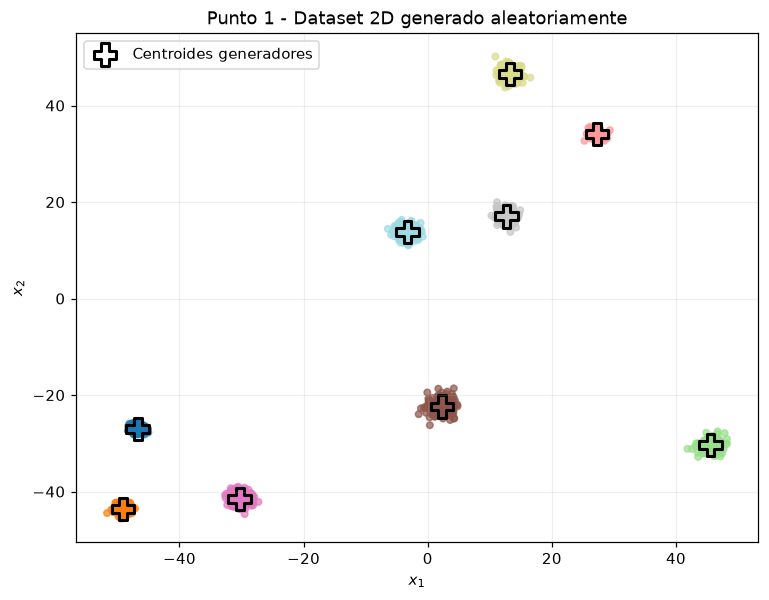

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X1[:, 0], X1[:, 1], c=y1_verdadero, cmap="tab20", s=18, alpha=0.7)
ax.scatter(centros1[:, 0], centros1[:, 1], marker="P", s=220,
           facecolors="none", edgecolors="black", linewidths=2,
           label="Centroides generadores")
ax.set_title("Dataset 2D generado aleatoriamente")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.legend()
guardar_fig("p1_01_dataset")
plt.show()

In [5]:
k1 = len(centros1)
kmeans1 = KMeans(n_clusters=k1, init="k-means++", n_init=10, random_state=SEMILLA)
etiquetas1 = kmeans1.fit_predict(X1)
centroides1 = kmeans1.cluster_centers_
conteos1 = resumen_por_cluster(etiquetas1, centroides1)
top5_1, distancias1 = cinco_puntos_mas_cercanos(X1, etiquetas1, centroides1, n=5)

print("Resultado de K-Means (2D)")
print(f"Numero de clusters    : {k1}")
print(f"Inercia final         : {kmeans1.inertia_:.4f}")
print(f"Iteraciones realizadas: {kmeans1.n_iter_}")
print("\nPuntos asignados por centroide aprendido:")
for i in range(k1):
    print(f"  Cluster {i:2d}: {conteos1[i]:4d} puntos | centroide = {np.round(centroides1[i], 3)}")

print("\n5 puntos mas cercanos a cada centroide:")
for i in range(k1):
    print(f"\n  Cluster {i} (centroide {np.round(centroides1[i], 3)}):")
    for puesto, idx in enumerate(top5_1[i], start=1):
        d = np.linalg.norm(X1[idx] - centroides1[i])
        print(f"    {puesto}. indice={idx:4d} | punto={np.round(X1[idx], 3)} | distancia={d:.5f}")

PUNTO 1 - Resultado de K-Means (2D)
Numero de clusters    : 9
Inercia final         : 2805.4122
Iteraciones realizadas: 2

Puntos asignados por centroide aprendido:
  Cluster  0:  172 puntos | centroide = [13.27  46.628]
  Cluster  1:  171 puntos | centroide = [-30.191 -41.477]
  Cluster  2:  203 puntos | centroide = [  2.292 -22.25 ]
  Cluster  3:  195 puntos | centroide = [-3.324 13.764]
  Cluster  4:  101 puntos | centroide = [ 45.545 -30.338]
  Cluster  5:  220 puntos | centroide = [-46.755 -26.954]
  Cluster  6:  127 puntos | centroide = [27.247 34.095]
  Cluster  7:  145 puntos | centroide = [12.737 17.094]
  Cluster  8:  152 puntos | centroide = [-49.151 -43.606]

5 puntos mas cercanos a cada centroide:

  Cluster 0 (centroide [13.27  46.628]):
    1. indice=1174 | punto=[13.284 46.687] | distancia=0.06029
    2. indice=1110 | punto=[13.262 46.705] | distancia=0.07724
    3. indice=1462 | punto=[13.15  46.712] | distancia=0.14714
    4. indice=1204 | punto=[13.231 46.8  ] | dist

Figura guardada en: /home/zahir/IA1/Unsupervised/lab/figs/p1_02_resultado.png


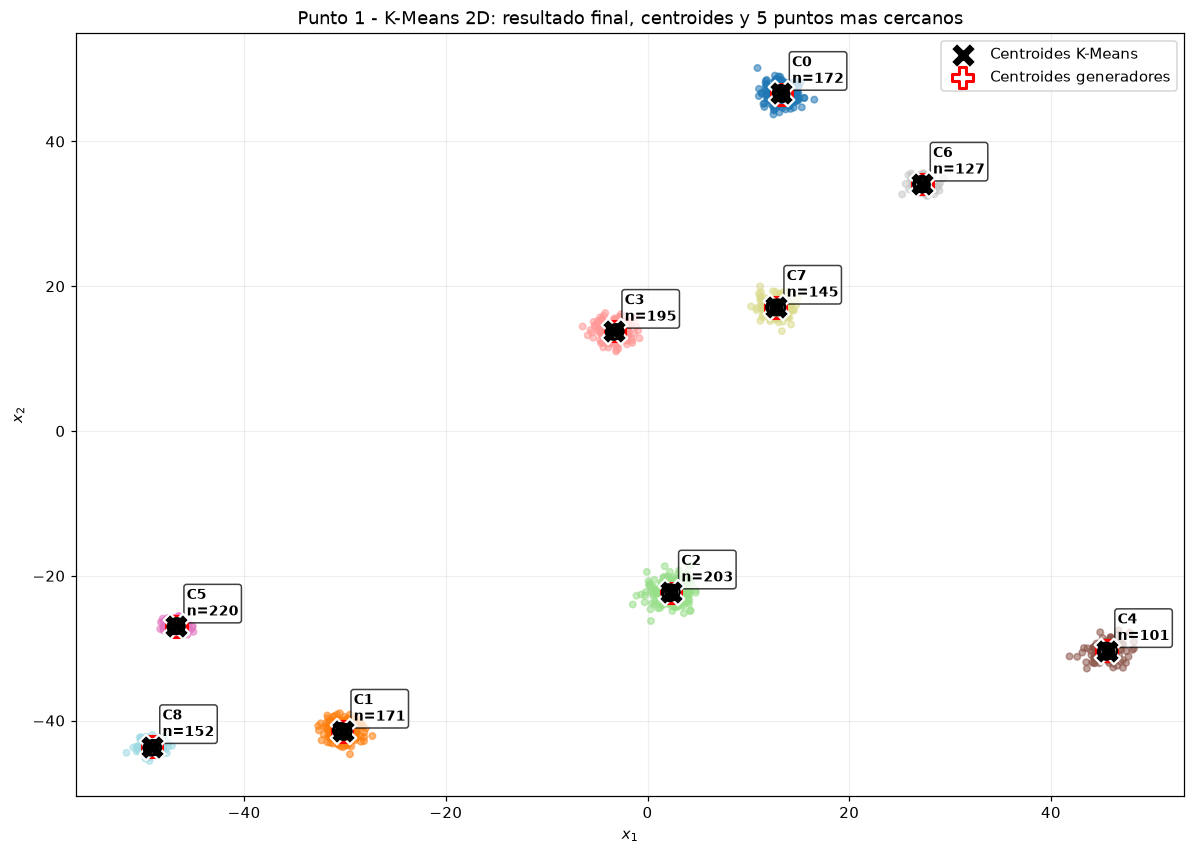

In [6]:
fig, ax = plt.subplots(figsize=(13, 9))
ax.scatter(X1[:, 0], X1[:, 1], c=etiquetas1, cmap="tab20", s=18, alpha=0.55)
ax.scatter(centroides1[:, 0], centroides1[:, 1], marker="X", s=280, c="black",
           edgecolors="white", linewidths=1.5, label="Centroides K-Means", zorder=6)
ax.scatter(centros1[:, 0], centros1[:, 1], marker="P", s=180, facecolors="none",
           edgecolors="red", linewidths=2, label="Centroides generadores", zorder=5)

for i, indices in top5_1.items():
    if len(indices) == 0:
        continue
    pts = X1[indices]
    ax.scatter(pts[:, 0], pts[:, 1], s=90, facecolors="none",
               edgecolors="black", linewidths=1.4, zorder=7)
    cx, cy = centroides1[i]
    ax.annotate(f"C{i}\nn={conteos1[i]}", (cx, cy), xytext=(7, 7),
                textcoords="offset points", fontsize=9, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.75))

ax.set_title("K-Means 2D: resultado final, centroides y 5 puntos mas cercanos")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.legend(loc="best")
guardar_fig("p1_02_resultado")
plt.show()

Figura guardada en: /home/zahir/IA1/Unsupervised/lab/figs/p1_03_proceso.png


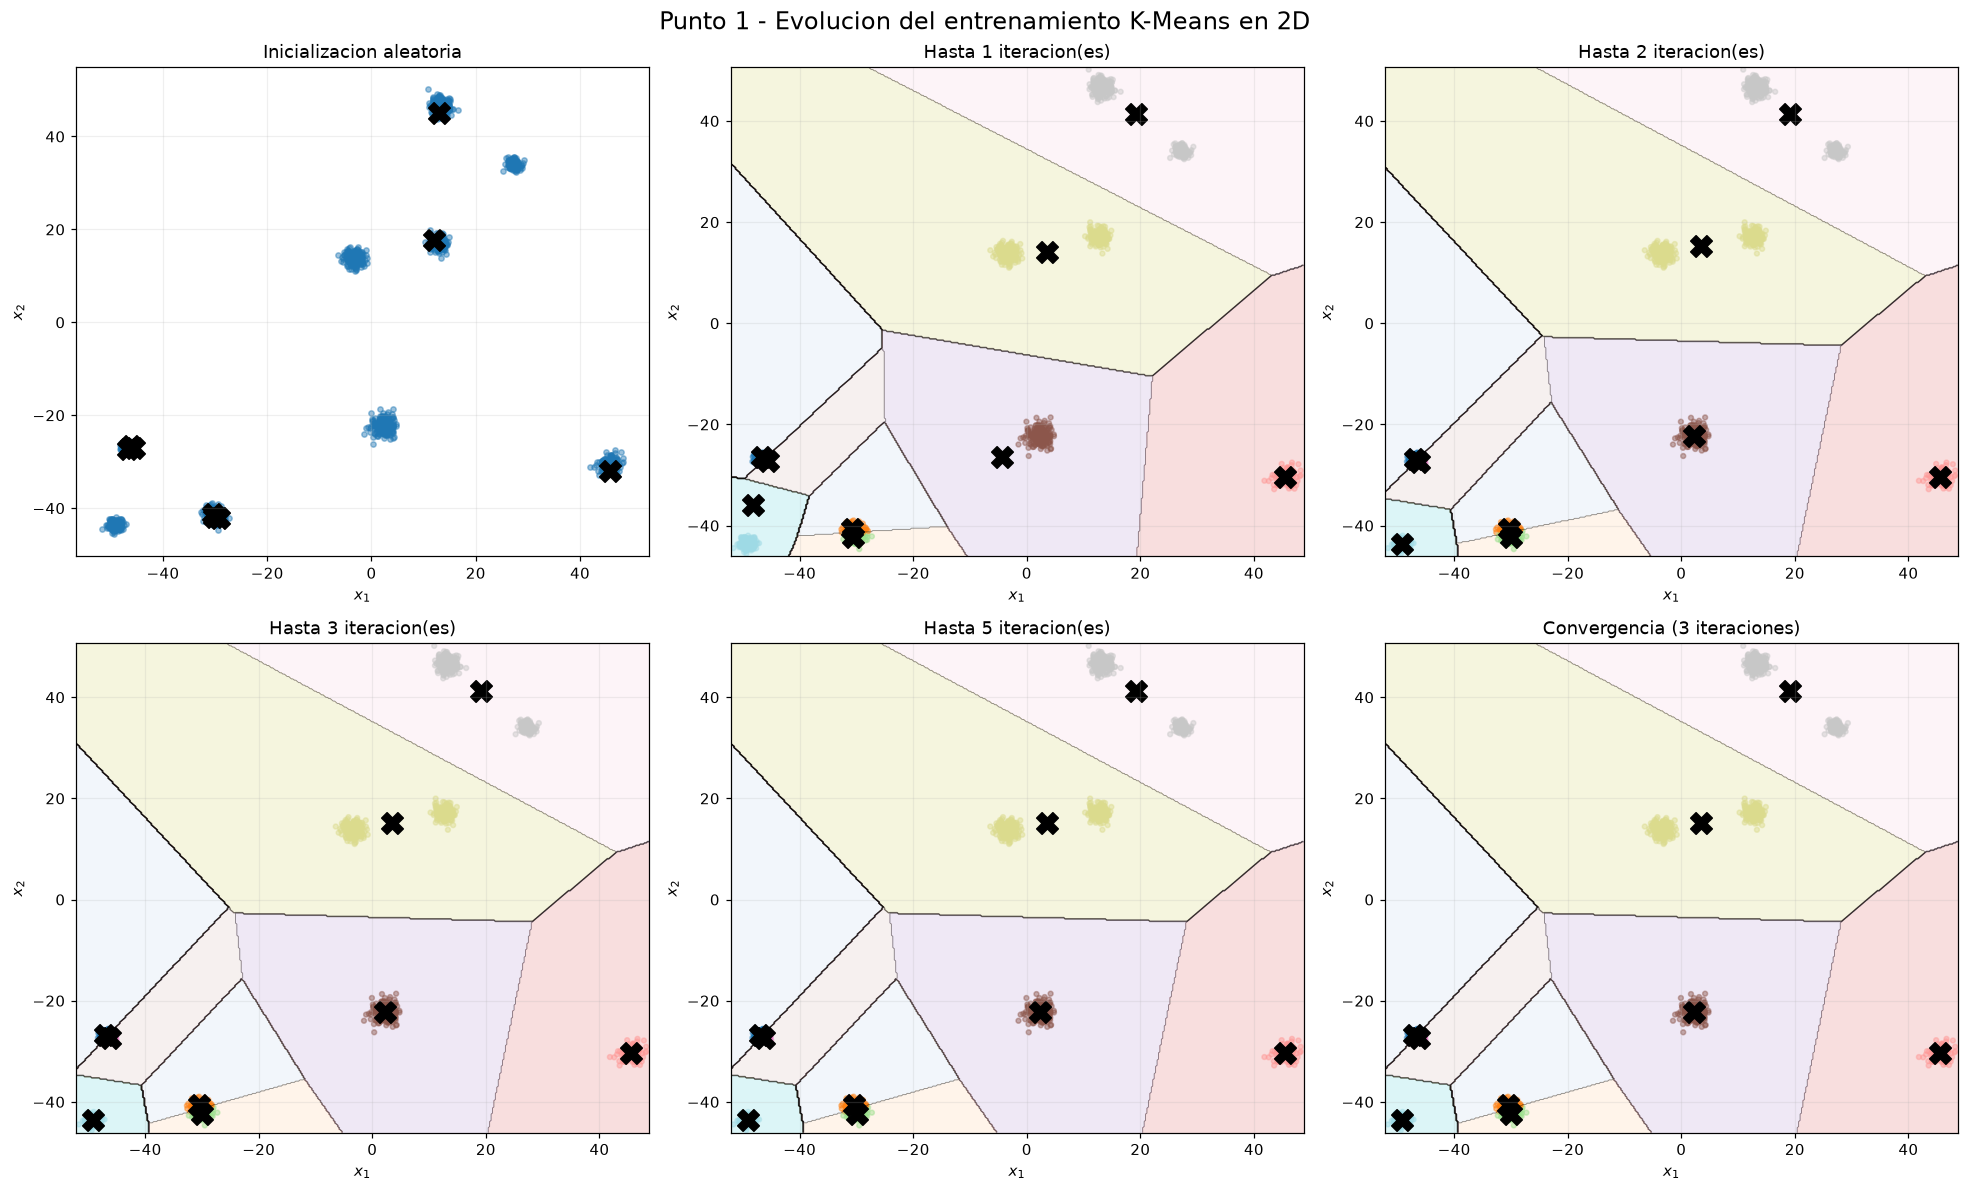

In [7]:
rng_proc = np.random.default_rng(123)
indices_init = rng_proc.choice(len(X1), size=k1, replace=False)
centros_iniciales1 = X1[indices_init].copy()

pasos = [1, 2, 3, 5]
modelos_proc = []
for max_iter in pasos:
    m = KMeans(n_clusters=k1, init=centros_iniciales1, n_init=1,
               max_iter=max_iter, algorithm="lloyd", random_state=123).fit(X1)
    modelos_proc.append((max_iter, m))

modelo_conv = KMeans(n_clusters=k1, init=centros_iniciales1, n_init=1,
                     max_iter=300, algorithm="lloyd", random_state=123).fit(X1)


def frontera_decision(ax, modelo, X):
    mins = X.min(axis=0) - 0.5
    maxs = X.max(axis=0) + 0.5
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], 400),
                         np.linspace(mins[1], maxs[1], 400))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.15, cmap="tab20")
    ax.contour(xx, yy, Z, linewidths=0.6, colors="k", alpha=0.4)


fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.ravel()

axes[0].scatter(X1[:, 0], X1[:, 1], s=12, alpha=0.45)
axes[0].scatter(centros_iniciales1[:, 0], centros_iniciales1[:, 1],
                marker="X", s=200, c="black")
axes[0].set_title("Inicializacion aleatoria")

for ax, (max_iter, modelo) in zip(axes[1:5], modelos_proc):
    frontera_decision(ax, modelo, X1)
    ax.scatter(X1[:, 0], X1[:, 1], c=modelo.labels_, cmap="tab20", s=10, alpha=0.45)
    ax.scatter(modelo.cluster_centers_[:, 0], modelo.cluster_centers_[:, 1],
               marker="X", s=200, c="black")
    ax.set_title(f"Hasta {max_iter} iteracion(es)")

frontera_decision(axes[5], modelo_conv, X1)
axes[5].scatter(X1[:, 0], X1[:, 1], c=modelo_conv.labels_, cmap="tab20", s=10, alpha=0.45)
axes[5].scatter(modelo_conv.cluster_centers_[:, 0], modelo_conv.cluster_centers_[:, 1],
                marker="X", s=200, c="black")
axes[5].set_title(f"Convergencia ({modelo_conv.n_iter_} iteraciones)")

for ax in axes:
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
plt.suptitle("Evolucion del entrenamiento K-Means en 2D", fontsize=16)
plt.tight_layout()
guardar_fig("p1_03_proceso")
plt.show()

# K-Means sobre datos generados aleatoriamente en 3D

In [8]:
SEMILLA_P2 = None
rng2 = np.random.default_rng(SEMILLA_P2)

X2, y2_verdadero, centros2, std2, n_puntos2 = generar_dataset(
    dimensiones=3, rng=rng2, limite=50.0, distancia_minima=11.0,
    std_min=0.60, std_max=2.00, puntos_min=70, puntos_max=220,
)

print("Dataset aleatorio generado (3D)")
print(f"Numero de centroides generados : {len(centros2)}")
print(f"Numero total de puntos         : {len(X2)}")
print("\nPosiciones de los centroides generadores 3D:")
for i, c in enumerate(centros2):
    print(f"  Centroide {i:2d}: {np.round(c, 3)}")
print("\nDispersion (sigma) por centroide 3D:")
print(np.round(std2, 3))
print("\nNumero de puntos generados por centroide 3D:")
print(n_puntos2)

PUNTO 2 - Dataset aleatorio generado (3D)
Numero de centroides generados : 19
Numero total de puntos         : 2928

Posiciones de los centroides generadores 3D:
  Centroide  0: [39.802 18.04  26.868]
  Centroide  1: [ 29.713 -25.694  25.769]
  Centroide  2: [  0.074  19.096 -10.775]
  Centroide  3: [ 8.833 11.555  5.675]
  Centroide  4: [14.554 38.182 10.269]
  Centroide  5: [ 20.217 -13.093  44.474]
  Centroide  6: [  5.401 -11.449 -43.396]
  Centroide  7: [ 13.666 -48.141  -6.245]
  Centroide  8: [-24.901  10.958  -2.943]
  Centroide  9: [30.804 -5.17  30.211]
  Centroide 10: [ 25.279 -12.264   1.565]
  Centroide 11: [ -4.585  41.499 -41.947]
  Centroide 12: [-42.08    6.787  46.149]
  Centroide 13: [-16.079   8.81  -48.961]
  Centroide 14: [-2.435 26.995 10.785]
  Centroide 15: [ 37.41   15.91  -26.493]
  Centroide 16: [-25.769 -24.356  47.167]
  Centroide 17: [-28.676  18.163 -16.53 ]
  Centroide 18: [ 48.75  -16.994  18.507]

Dispersion (sigma) por centroide 3D:
[1.355 1.597 1.39

Figura guardada en: /home/zahir/IA1/Unsupervised/lab/figs/p2_01_dataset.png


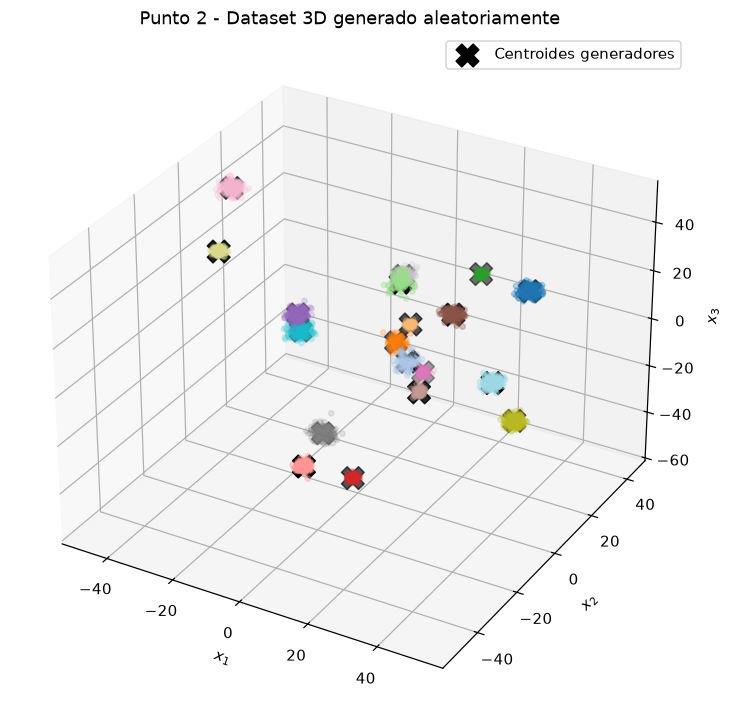

In [9]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X2[:, 0], X2[:, 1], X2[:, 2], c=y2_verdadero, cmap="tab20", s=12, alpha=0.6)
ax.scatter(centros2[:, 0], centros2[:, 1], centros2[:, 2], marker="X", s=220,
           c="black", label="Centroides generadores")
ax.set_title("Dataset 3D generado aleatoriamente")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$x_3$")
ax.legend()
guardar_fig("p2_01_dataset")
plt.show()

In [10]:
k2 = len(centros2)
kmeans2 = KMeans(n_clusters=k2, init="k-means++", n_init=10, random_state=SEMILLA)
etiquetas2 = kmeans2.fit_predict(X2)
centroides2 = kmeans2.cluster_centers_
conteos2 = resumen_por_cluster(etiquetas2, centroides2)
top5_2, distancias2 = cinco_puntos_mas_cercanos(X2, etiquetas2, centroides2, n=5)

print("Resultado de K-Means (3D)")
print(f"Numero de clusters    : {k2}")
print(f"Inercia final         : {kmeans2.inertia_:.4f}")
print(f"Iteraciones realizadas: {kmeans2.n_iter_}")
print("\nPuntos asignados por centroide aprendido:")
for i in range(k2):
    print(f"  Cluster {i:2d}: {conteos2[i]:4d} puntos | centroide = {np.round(centroides2[i], 3)}")

print("\n5 puntos mas cercanos a cada centroide:")
for i in range(k2):
    print(f"\n  Cluster {i} (centroide {np.round(centroides2[i], 3)}):")
    for puesto, idx in enumerate(top5_2[i], start=1):
        d = np.linalg.norm(X2[idx] - centroides2[i])
        print(f"    {puesto}. indice={idx:4d} | punto={np.round(X2[idx], 3)} | distancia={d:.5f}")

PUNTO 2 - Resultado de K-Means (3D)
Numero de clusters    : 19
Inercia final         : 13629.3732
Iteraciones realizadas: 2

Puntos asignados por centroide aprendido:
  Cluster  0:   97 puntos | centroide = [  0.169  19.152 -10.707]
  Cluster  1:   86 puntos | centroide = [ 20.127 -12.956  44.461]
  Cluster  2:  195 puntos | centroide = [-28.746  17.946 -16.487]
  Cluster  3:  182 puntos | centroide = [ 13.576 -48.111  -6.227]
  Cluster  4:  192 puntos | centroide = [-25.776 -24.317  47.253]
  Cluster  5:  173 puntos | centroide = [  5.374 -11.5   -43.324]
  Cluster  6:  204 puntos | centroide = [39.714 17.915 26.924]
  Cluster  7:  210 puntos | centroide = [ 37.587  15.82  -26.501]
  Cluster  8:  166 puntos | centroide = [ 48.885 -17.084  18.681]
  Cluster  9:  187 puntos | centroide = [14.56  38.163 10.296]
  Cluster 10:  175 puntos | centroide = [-42.04    6.798  46.288]
  Cluster 11:  174 puntos | centroide = [-15.984   8.983 -48.955]
  Cluster 12:  133 puntos | centroide = [ -4.55

Figura guardada en: /home/zahir/IA1/Unsupervised/lab/figs/p2_02_resultado.png


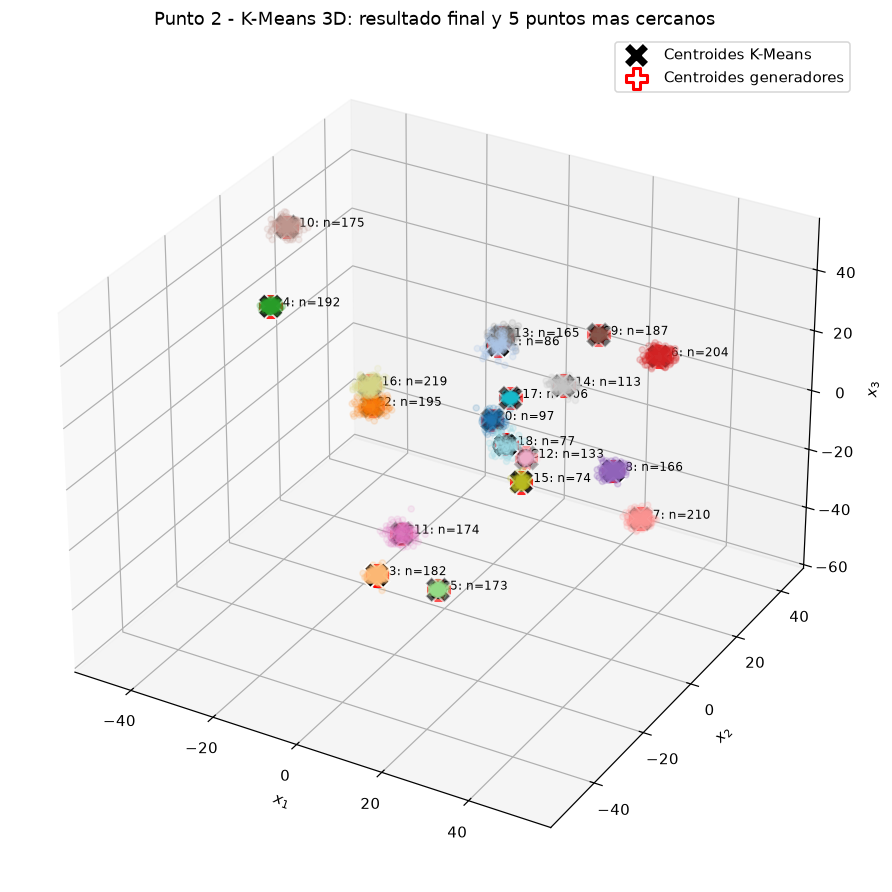

In [11]:
fig = plt.figure(figsize=(13, 10))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X2[:, 0], X2[:, 1], X2[:, 2], c=etiquetas2, cmap="tab20", s=16, alpha=0.5)
ax.scatter(centroides2[:, 0], centroides2[:, 1], centroides2[:, 2], marker="X",
           s=280, c="black", edgecolors="white", linewidths=1.2, label="Centroides K-Means")
ax.scatter(centros2[:, 0], centros2[:, 1], centros2[:, 2], marker="P", s=180,
           facecolors="none", edgecolors="red", linewidths=2, label="Centroides generadores")

for i, indices in top5_2.items():
    if len(indices) == 0:
        continue
    pts = X2[indices]
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=90, facecolors="none",
               edgecolors="black", linewidths=1.4)
    cx, cy, cz = centroides2[i]
    ax.text(cx, cy, cz, f" C{i}: n={conteos2[i]}", fontsize=8)

ax.set_title("K-Means 3D: resultado final y 5 puntos mas cercanos")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$x_3$")
ax.legend(loc="best")
guardar_fig("p2_02_resultado")
plt.show()

Figura guardada en: /home/zahir/IA1/Unsupervised/lab/figs/p2_03_proceso.png


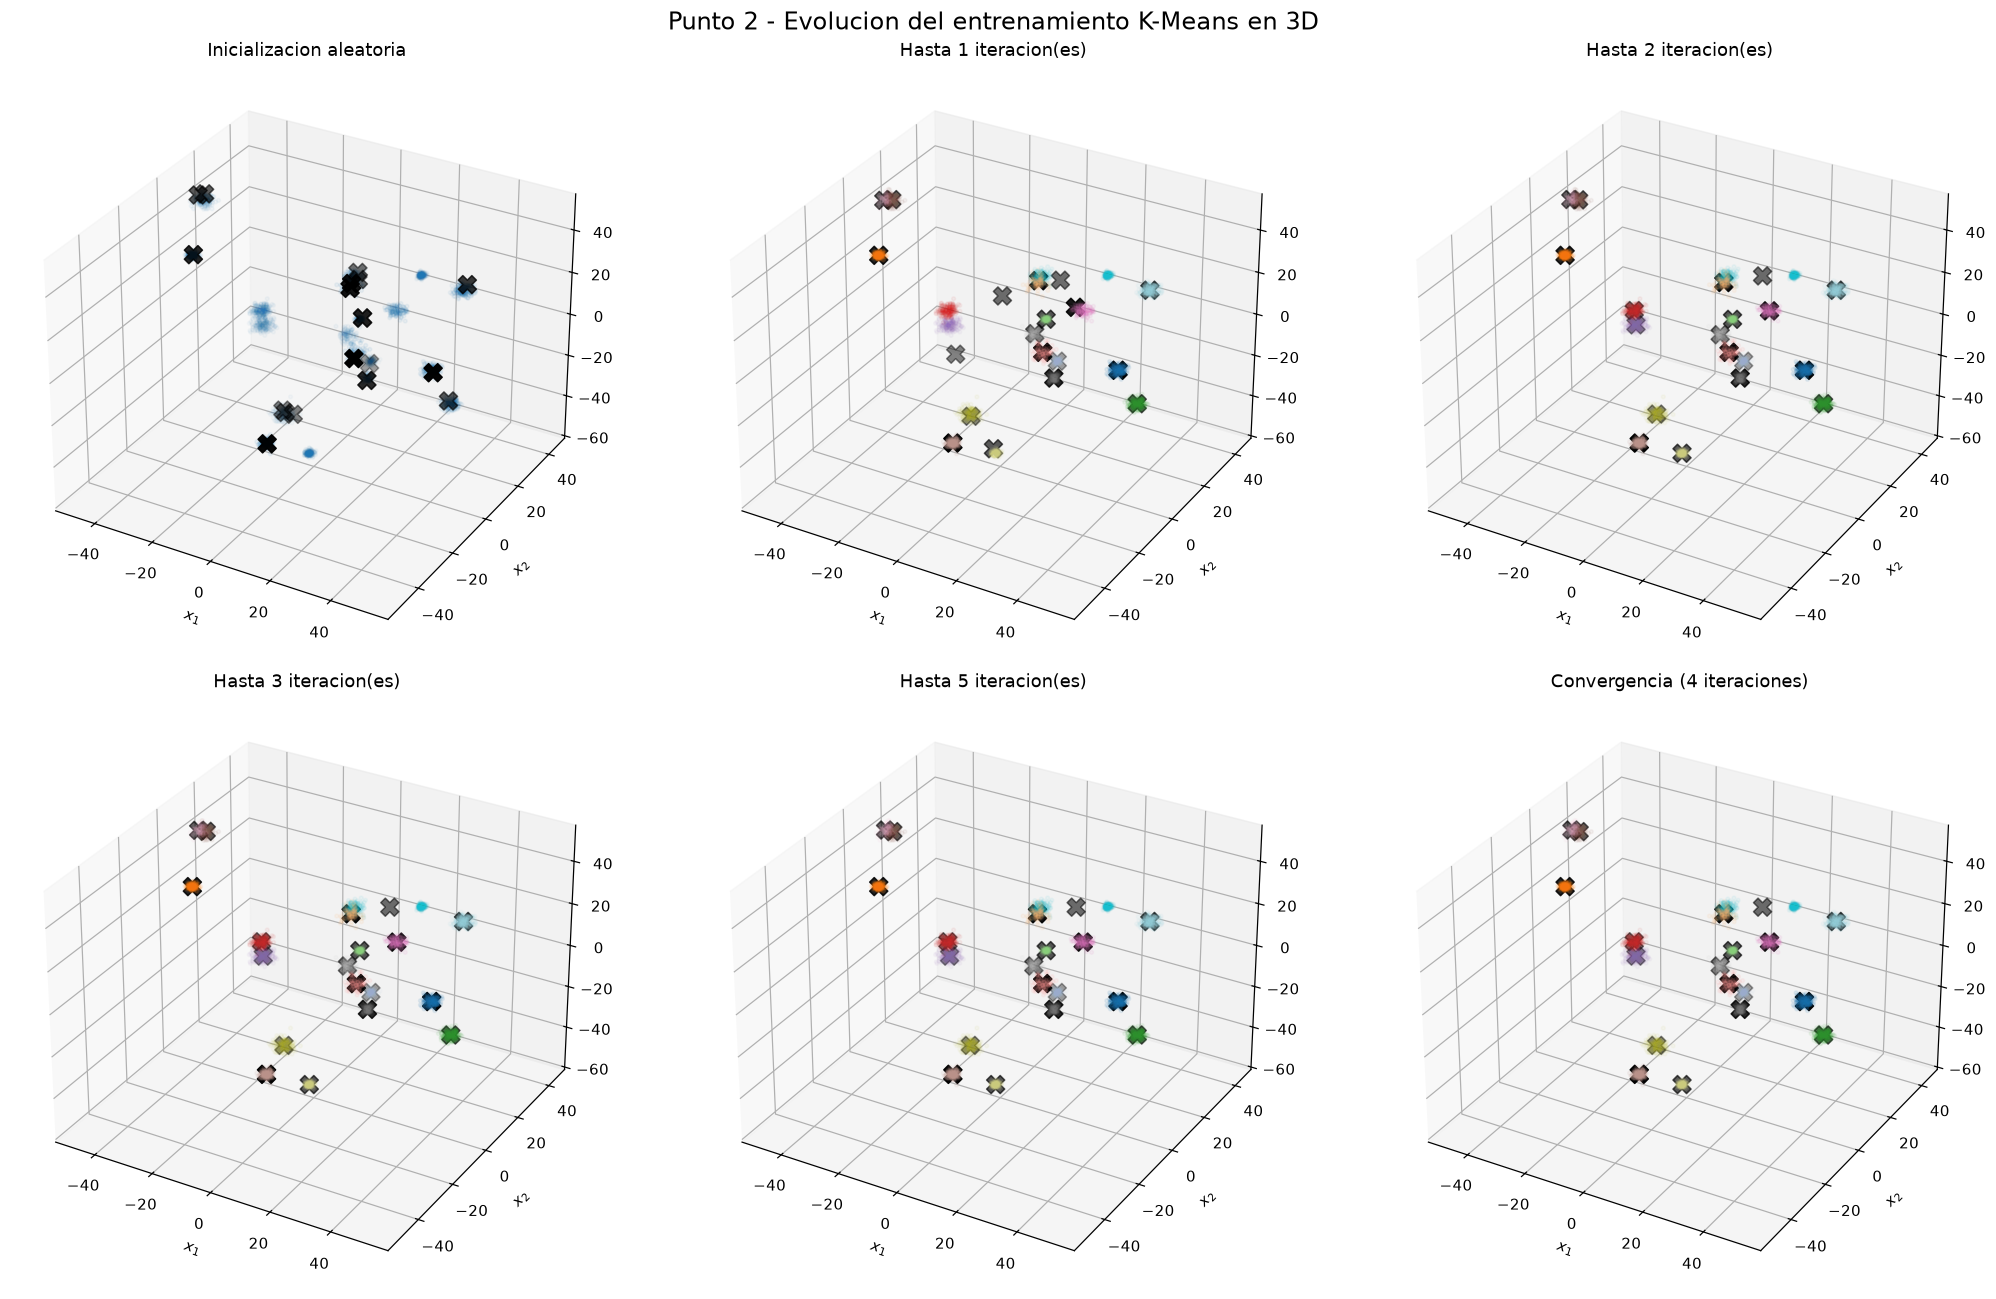

In [12]:
rng_proc3 = np.random.default_rng(123)
indices_init3 = rng_proc3.choice(len(X2), size=k2, replace=False)
centros_iniciales2 = X2[indices_init3].copy()

modelos_proc3 = []
for max_iter in pasos:
    m = KMeans(n_clusters=k2, init=centros_iniciales2, n_init=1,
               max_iter=max_iter, algorithm="lloyd", random_state=123).fit(X2)
    modelos_proc3.append((max_iter, m))

modelo_conv3 = KMeans(n_clusters=k2, init=centros_iniciales2, n_init=1,
                      max_iter=300, algorithm="lloyd", random_state=123).fit(X2)

fig = plt.figure(figsize=(19, 12))

ax = fig.add_subplot(2, 3, 1, projection="3d")
ax.scatter(X2[:, 0], X2[:, 1], X2[:, 2], s=6, alpha=0.25)
ax.scatter(centros_iniciales2[:, 0], centros_iniciales2[:, 1], centros_iniciales2[:, 2],
           marker="X", s=140, c="black")
ax.set_title("Inicializacion aleatoria")

for pos, (max_iter, modelo) in enumerate(modelos_proc3, start=2):
    ax = fig.add_subplot(2, 3, pos, projection="3d")
    ax.scatter(X2[:, 0], X2[:, 1], X2[:, 2], c=modelo.labels_, cmap="tab20", s=6, alpha=0.30)
    ax.scatter(modelo.cluster_centers_[:, 0], modelo.cluster_centers_[:, 1],
               modelo.cluster_centers_[:, 2], marker="X", s=140, c="black")
    ax.set_title(f"Hasta {max_iter} iteracion(es)")

ax = fig.add_subplot(2, 3, 6, projection="3d")
ax.scatter(X2[:, 0], X2[:, 1], X2[:, 2], c=modelo_conv3.labels_, cmap="tab20", s=6, alpha=0.30)
ax.scatter(modelo_conv3.cluster_centers_[:, 0], modelo_conv3.cluster_centers_[:, 1],
           modelo_conv3.cluster_centers_[:, 2], marker="X", s=140, c="black")
ax.set_title(f"Convergencia ({modelo_conv3.n_iter_} iteraciones)")

for ax in fig.axes:
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
plt.suptitle("Evolucion del entrenamiento K-Means en 3D", fontsize=16)
plt.tight_layout()
guardar_fig("p2_03_proceso")
plt.show()

# Aprendizaje semisupervisado y activo sobre audio sin etiquetas

## 3.1 Descripción del corpus

Se utiliza **Speech Commands v0.02** de Google, un corpus de audio de palabras
habladas. Características:

| Propiedad | Valor |
|---|---|
| Muestras totales | ~105.829 audios (.wav) |
| Duración por audio | ~1 segundo, 16 kHz mono |
| Clases (palabras) | 35 |
| Etiquetas | no usadas para entrenar (solo para simular anotación y evaluar) |

## 3.2 Extracción de características

Cada audio se transforma en un vector de longitud fija combinando estadísticos
temporales del **MFCC** y de sus derivadas primera y segunda. Con `N_MFCC = 40`
coeficientes y media + desviación estándar por coeficiente, la dimensión final
es `n = 40 * 2 * 3 = 240`.

Las características se calculan una sola vez y se guardan en `features/` para
no repetir el procesamiento en ejecuciones posteriores.

In [13]:
DATASET_ROOT = Path.home() / ".cache" / "speech_commands"
DATASET_ROOT.mkdir(parents=True, exist_ok=True)
N_MFCC = 40
DIM_FEATURES = N_MFCC * 2 * 3
NUM_WORKERS = min(12, os.cpu_count() or 4)

print(f"Raiz del dataset     : {DATASET_ROOT}")
print(f"Caracteristicas (n)  : {DIM_FEATURES}")
print(f"Workers para carga   : {NUM_WORKERS}")

Raiz del dataset     : /home/zahir/.cache/speech_commands
Caracteristicas (n)  : 240
Workers para carga   : 12


In [14]:
def cargar_wav(ruta):
    sr, data = wavfile.read(str(ruta))
    if data.dtype == np.int16:
        data = data.astype(np.float32) / 32768.0
    elif data.dtype == np.int32:
        data = data.astype(np.float32) / 2147483648.0
    elif data.dtype == np.uint8:
        data = (data.astype(np.float32) - 128.0) / 128.0
    else:
        data = data.astype(np.float32)
    data = np.atleast_2d(data)
    return torch.from_numpy(data), sr


def obtener_rutas(subset, root=DATASET_ROOT):
    ds = SPEECHCOMMANDS(root=str(root), download=True, subset=subset)
    return list(ds._walker)


class SpeechCommandsFeatures(Dataset):
    def __init__(self, rutas, n_mfcc=N_MFCC):
        self.rutas = rutas
        self.n_mfcc = n_mfcc
        self._mfcc = None

    def _transformaciones(self, sample_rate):
        if self._mfcc is None:
            melkwargs = {"n_fft": 1024, "hop_length": 256, "n_mels": 64, "power": 2.0}
            self._mfcc = torchaudio.transforms.MFCC(
                sample_rate=sample_rate, n_mfcc=self.n_mfcc, melkwargs=melkwargs
            )
        return self._mfcc

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, idx):
        ruta = self.rutas[idx]
        wav, sr = cargar_wav(ruta)
        label = Path(ruta).parent.name
        wav = wav.mean(dim=0, keepdim=True)
        
        objetivo = 16000
        if wav.shape[-1] > objetivo:
            wav = wav[..., :objetivo]
        elif wav.shape[-1] < objetivo:
            wav = F.pad(wav, (0, objetivo - wav.shape[-1]))

        wav = wav / (wav.abs().max() + 1e-9)

        mfcc = self._transformaciones(sr)(wav)
        d1 = torchaudio.functional.compute_deltas(mfcc)
        d2 = torchaudio.functional.compute_deltas(d1)

        def est(t):
            return torch.cat([t.mean(dim=-1), t.std(dim=-1)], dim=-1).reshape(-1)

        features = torch.cat([est(mfcc), est(d1), est(d2)], dim=0).float()
        return features, label, idx


def rutas_cache(subset):
    return DIR_FEATURES / f"{subset}_{N_MFCC}.npz"


def extraer_caracteristicas(subset, root=DATASET_ROOT, batch_size=128):
    cache = rutas_cache(subset)
    if cache.exists():
        data = np.load(cache, allow_pickle=True)
        print(f"[cache] {subset}: X={data['X'].shape} cargado desde {cache}")
        return data["X"], data["y"], data["idx"], list(data["rutas"])

    t0 = time.time()
    rutas = obtener_rutas(subset, root)
    dataset = SpeechCommandsFeatures(rutas)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False,
                        num_workers=NUM_WORKERS)
    X_partes, y_partes, idx_partes = [], [], []
    for features, labels, idxs in loader:
        X_partes.append(features.numpy().astype(np.float32))
        y_partes.extend(list(labels))
        idx_partes.append(idxs.numpy())

    X = np.concatenate(X_partes, axis=0)
    y = np.array(y_partes)
    idx = np.concatenate(idx_partes, axis=0)

    np.savez_compressed(cache, X=X, y=y, idx=idx, rutas=np.array(rutas, dtype=object))
    print(f"[{subset}] {len(X)} muestras, X={X.shape} en {time.time() - t0:.1f}s -> {cache}")
    return X, y, idx, rutas

In [15]:
X_train, y_train, idx_train, rutas_train = extraer_caracteristicas("training")
X_val, y_val, idx_val, rutas_val = extraer_caracteristicas("validation")
X_test, y_test, idx_test, rutas_test = extraer_caracteristicas("testing")

X_pool = np.vstack([X_train, X_val])
y_pool = np.concatenate([y_train, y_val])
rutas_pool = list(rutas_train) + list(rutas_val)

X_test_ = X_test
y_test_ = y_test

print("\nResumen del corpus procesado")
print("=" * 45)
print(f"Pool sin etiquetas (train+val): {X_pool.shape}")
print(f"Conjunto de prueba            : {X_test_.shape}")
print(f"Total de ejemplos m           : {len(X_pool) + len(X_test_)}")
print(f"Dimensiones n                 : {X_pool.shape[1]}")
print(f"Numero de clases              : {len(np.unique(y_pool))}")

[cache] training: X=(84843, 240) cargado desde /home/zahir/IA1/Unsupervised/lab/features/training_40.npz


[cache] validation: X=(9981, 240) cargado desde /home/zahir/IA1/Unsupervised/lab/features/validation_40.npz
[cache] testing: X=(11005, 240) cargado desde /home/zahir/IA1/Unsupervised/lab/features/testing_40.npz



Resumen del corpus procesado
Pool sin etiquetas (train+val): (94824, 240)
Conjunto de prueba            : (11005, 240)
Total de ejemplos m           : 105829
Dimensiones n                 : 240
Numero de clases              : 35


In [16]:
clases = np.unique(y_pool)
n_clases = len(clases)
print(f"Clases ({n_clases}): {list(clases)}")

Clases (35): [np.str_('backward'), np.str_('bed'), np.str_('bird'), np.str_('cat'), np.str_('dog'), np.str_('down'), np.str_('eight'), np.str_('five'), np.str_('follow'), np.str_('forward'), np.str_('four'), np.str_('go'), np.str_('happy'), np.str_('house'), np.str_('learn'), np.str_('left'), np.str_('marvin'), np.str_('nine'), np.str_('no'), np.str_('off'), np.str_('on'), np.str_('one'), np.str_('right'), np.str_('seven'), np.str_('sheila'), np.str_('six'), np.str_('stop'), np.str_('three'), np.str_('tree'), np.str_('two'), np.str_('up'), np.str_('visual'), np.str_('wow'), np.str_('yes'), np.str_('zero')]


Figura guardada en: /home/zahir/IA1/Unsupervised/lab/figs/p3_01_audio_ejemplos.png


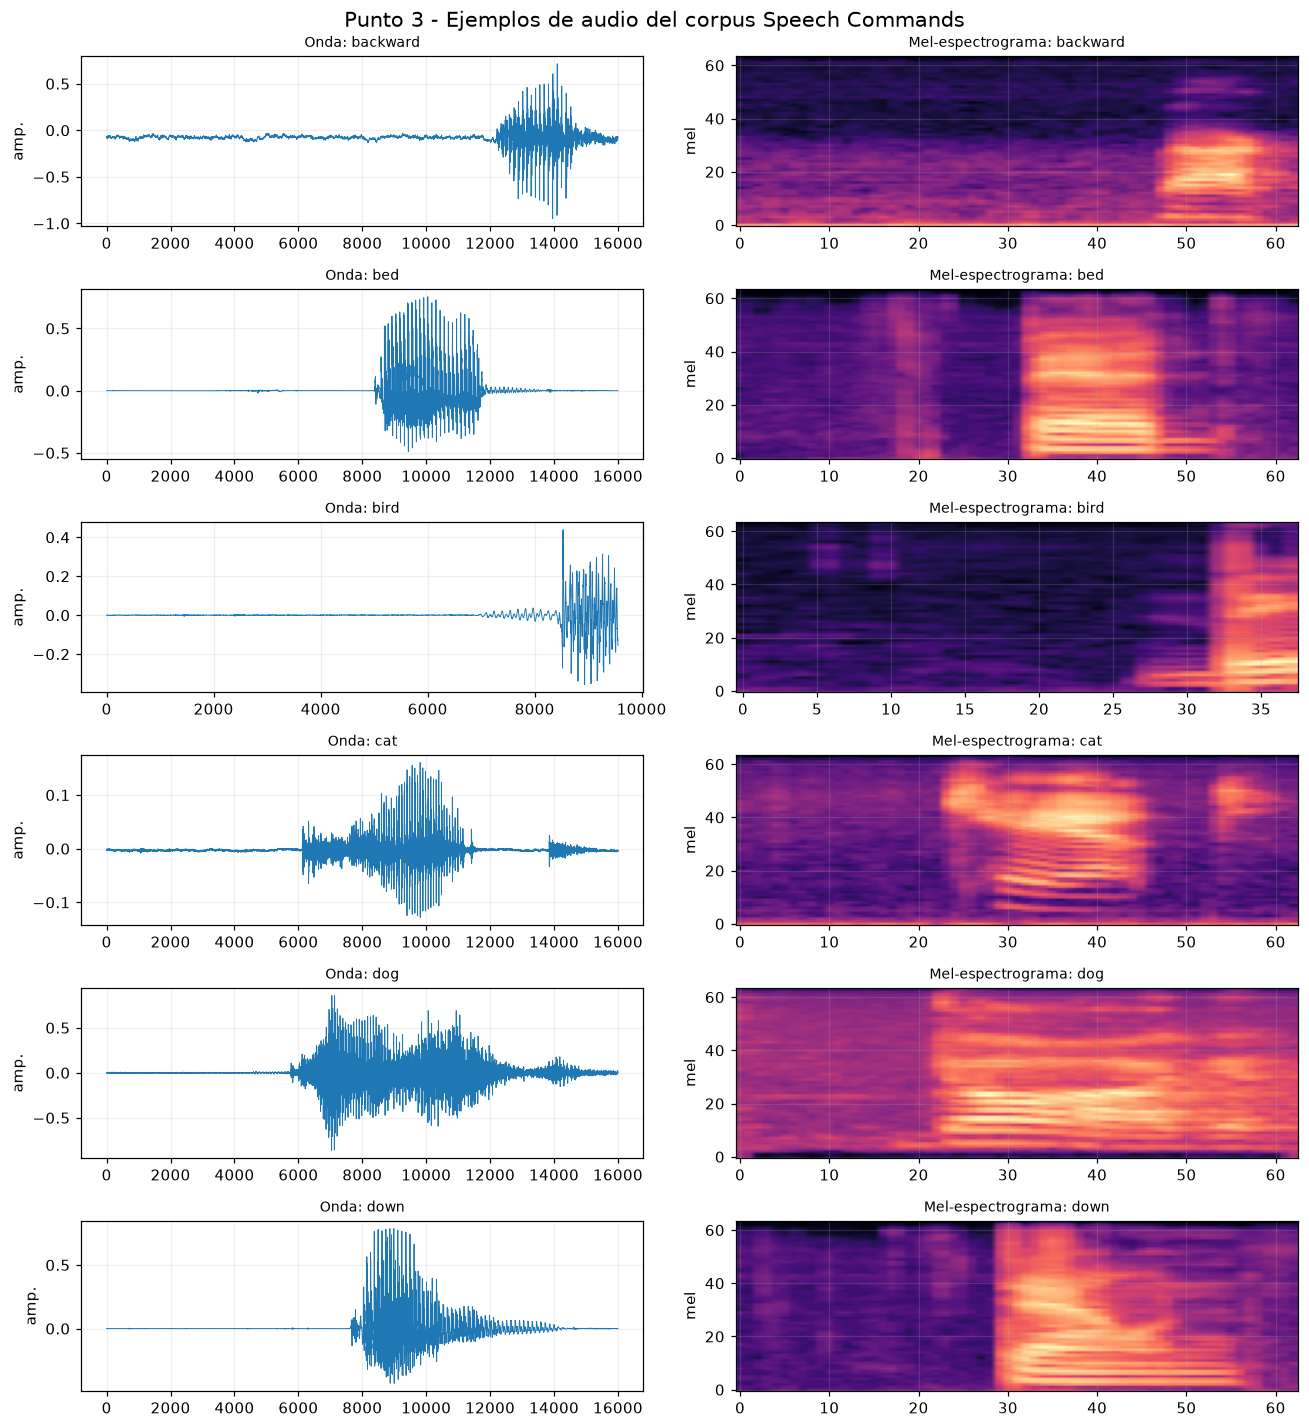

In [17]:
ejemplos_por_clase = {}
for i, palabra in enumerate(y_pool):
    ejemplos_por_clase.setdefault(palabra, i)

seleccion = list(ejemplos_por_clase.values())[:6]
fig, axes = plt.subplots(len(seleccion), 2, figsize=(12, 2.2 * len(seleccion)))
for fila, idx in enumerate(seleccion):
    wav, sr = cargar_wav(rutas_pool[idx])
    wav = wav.mean(dim=0)
    axes[fila, 0].plot(wav.numpy(), linewidth=0.6)
    axes[fila, 0].set_title(f"Onda: {y_pool[idx]}", fontsize=9)
    axes[fila, 0].set_ylabel("amp.")

    mel = torchaudio.transforms.MelSpectrogram(sample_rate=sr, n_fft=1024,
                                               hop_length=256, n_mels=64)(wav.unsqueeze(0))
    axes[fila, 1].imshow(20 * torch.log10(mel[0] + 1e-9).numpy(),
                         aspect="auto", origin="lower", cmap="magma")
    axes[fila, 1].set_title(f"Mel-espectrograma: {y_pool[idx]}", fontsize=9)
    axes[fila, 1].set_ylabel("mel")

plt.suptitle("Ejemplos de audio del corpus Speech Commands", fontsize=14)
plt.tight_layout()
guardar_fig("p3_01_audio_ejemplos")
plt.show()

In [18]:
scaler = StandardScaler()
X_pool_esc = scaler.fit_transform(X_pool).astype(np.float32)
X_test_esc = scaler.transform(X_test_).astype(np.float32)
print(f"Pool estandarizado : {X_pool_esc.shape}")
print(f"Test estandarizado : {X_test_esc.shape}")

Pool estandarizado : (94824, 240)
Test estandarizado : (11005, 240)


## Aprendizaje semisupervisado

In [19]:
def nuevo_clasificador(semilla=SEMILLA):
    return LogisticRegression(max_iter=200, random_state=semilla)


def propagar_por_kmeans(X, y, k, semilla=SEMILLA):
    km = MiniBatchKMeans(n_clusters=k, init="k-means++", n_init=10,
                         batch_size=2048, random_state=semilla).fit(X)
    lab = km.labels_
    dist = km.transform(X)
    y_prop = np.empty(len(X), dtype=object)
    reps = np.full(k, -1, dtype=int)
    for c in range(k):
        miembros = np.where(lab == c)[0]
        if len(miembros) == 0:
            continue
        reps[c] = miembros[np.argmin(dist[miembros, c])]
        y_prop[lab == c] = y[reps[c]]
    return km, lab, y_prop, reps

t0 = time.time()
kmeans_p3, lab_kmeans, y_propagadas, idx_representantes = propagar_por_kmeans(
    X_pool_esc, y_pool, k=n_clases
)
representantes_validos = idx_representantes[idx_representantes >= 0]
y_representantes = y_pool[representantes_validos]
print(f"K-Means (k={n_clases}) + propagacion en {time.time() - t0:.1f}s | "
      f"representantes etiquetados: {len(representantes_validos)}")

mascara_prop = np.array([isinstance(v, str) for v in y_propagadas])
clf_semi = nuevo_clasificador()
clf_semi.fit(X_pool_esc[mascara_prop], y_propagadas[mascara_prop].astype(str))
acc_semi = clf_semi.score(X_test_esc, y_test_)

_, _, y_prop100, reps100 = propagar_por_kmeans(X_pool_esc, y_pool, k=100)
mask100 = np.array([isinstance(v, str) for v in y_prop100])
clf_semi100 = nuevo_clasificador()
clf_semi100.fit(X_pool_esc[mask100], y_prop100[mask100].astype(str))
acc_semi100 = clf_semi100.score(X_test_esc, y_test_)

clf_repr = nuevo_clasificador()
clf_repr.fit(X_pool_esc[representantes_validos], y_representantes)
acc_repr = clf_repr.score(X_test_esc, y_test_)

acc_aleatorio = []
for intento in range(5):
    rng_int = np.random.default_rng(1000 + intento)
    idx_rand = rng_int.choice(len(X_pool_esc), size=len(representantes_validos), replace=False)
    clf = nuevo_clasificador()
    clf.fit(X_pool_esc[idx_rand], y_pool[idx_rand])
    acc_aleatorio.append(clf.score(X_test_esc, y_test_))
acc_aleatorio = float(np.mean(acc_aleatorio))

t0 = time.time()
clf_oraculo = nuevo_clasificador()
clf_oraculo.fit(X_pool_esc, y_pool)
acc_oraculo = clf_oraculo.score(X_test_esc, y_test_)
print(f"Clasificador con todas las etiquetas (techo) en {time.time() - t0:.1f}s")

print("\nAPRENDIZAJE SEMISUPERVISADO - Resultados")
print(f"Solo representantes ({len(representantes_validos)} etiquetas)      : {acc_repr:.4f}")
print(f"{len(representantes_validos)} aleatorias (prom. 5)              : {acc_aleatorio:.4f}")
print(f"Propagacion clusters k={n_clases}                  : {acc_semi:.4f}")
print(f"Propagacion clusters k=100                  : {acc_semi100:.4f}")
print(f"Techo (todas las etiquetas del pool)        : {acc_oraculo:.4f}")

K-Means (k=35) + propagacion en 1.8s | representantes etiquetados: 35


Clasificador con todas las etiquetas (techo) en 34.9s

APRENDIZAJE SEMISUPERVISADO - Resultados
Solo representantes (35 etiquetas)      : 0.0612
35 aleatorias (prom. 5)              : 0.0581
Propagacion clusters k=35                  : 0.0509
Propagacion clusters k=100                  : 0.0612
Techo (todas las etiquetas del pool)        : 0.5830


In [20]:
SEED_AUTO = 1000
rng_auto = np.random.default_rng(2024)
idx_seed = rng_auto.choice(len(X_pool_esc), size=SEED_AUTO, replace=False)

clf_seed = nuevo_clasificador()
clf_seed.fit(X_pool_esc[idx_seed], y_pool[idx_seed])
acc_seed = clf_seed.score(X_test_esc, y_test_)

t0 = time.time()
y_semi = np.full(len(X_pool_esc), -1, dtype=object)
y_semi[idx_seed] = y_pool[idx_seed]
self_train = SelfTrainingClassifier(
    nuevo_clasificador(), threshold=0.7, max_iter=3, verbose=False
)
self_train.fit(X_pool_esc, y_semi)
acc_self = self_train.score(X_test_esc, y_test_)
print(f"Autoentrenamiento (semilla={SEED_AUTO}) en {time.time() - t0:.1f}s")
print(f"  Solo semilla etiquetada : {acc_seed:.4f}")
print(f"  Con pseudo-etiquetado    : {acc_self:.4f}")

Autoentrenamiento (semilla=1000) en 120.0s
  Solo semilla etiquetada : 0.2405
  Con pseudo-etiquetado    : 0.2411


Figura guardada en: /home/zahir/IA1/Unsupervised/lab/figs/p3_02_semisupervisado.png


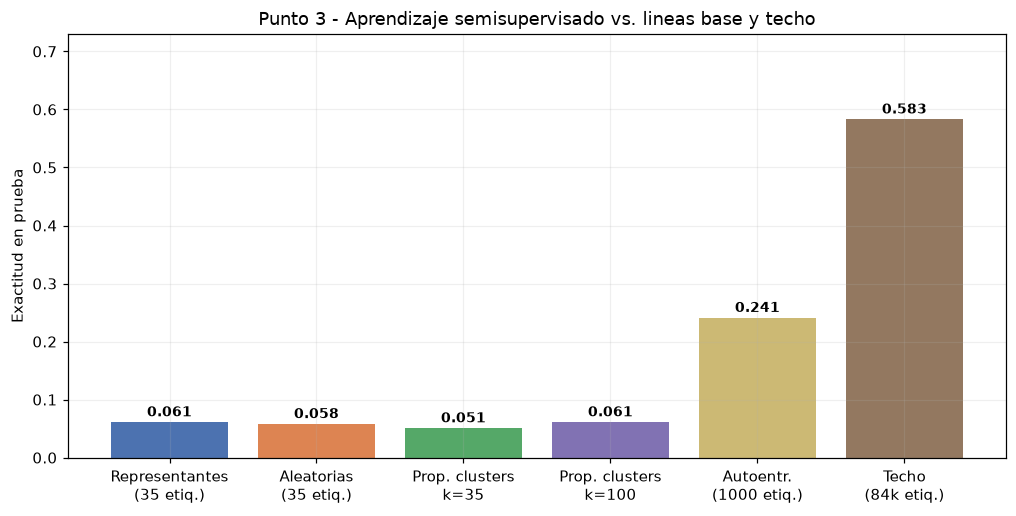

In [21]:
fig, ax = plt.subplots(figsize=(11, 5))
nombres = ["Representantes\n(35 etiq.)", "Aleatorias\n(35 etiq.)",
           "Prop. clusters\nk=35", "Prop. clusters\nk=100",
           "Autoentr.\n(1000 etiq.)", "Techo\n(84k etiq.)"]
valores = [acc_repr, acc_aleatorio, acc_semi, acc_semi100, acc_self, acc_oraculo]
colores = ["#4c72b0", "#dd8452", "#55a868", "#8172b3", "#ccb974", "#937860"]
barras = ax.bar(nombres, valores, color=colores)
for b, v in zip(barras, valores):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}",
            ha="center", fontweight="bold", fontsize=9)
ax.set_ylabel("Exactitud en prueba")
ax.set_ylim(0, max(valores) * 1.25 + 1e-3)
ax.set_title("Aprendizaje semisupervisado vs. lineas base y techo")
guardar_fig("p3_02_semisupervisado")
plt.show()

## Aprendizaje activo

In [22]:
def aprendizaje_activo(idx_inicial, rondas, lote, modo="margen", semilla=SEMILLA):
    rng_ac = np.random.default_rng(semilla)
    etiquetados = list(idx_inicial)
    no_etiquetados = np.setdiff1d(np.arange(len(X_pool_esc)), np.array(etiquetados))
    historial = []
    for ronda in range(rondas + 1):
        clf = nuevo_clasificador().fit(X_pool_esc[etiquetados], y_pool[etiquetados])
        historial.append(clf.score(X_test_esc, y_test_))
        if ronda == rondas:
            break
        if modo == "margen":
            probas = clf.predict_proba(X_pool_esc[no_etiquetados])
            dos_mayores = np.sort(probas, axis=1)[:, -2:]
            margen = dos_mayores[:, 1] - dos_mayores[:, 0]
            elegidos = no_etiquetados[np.argsort(margen)[:lote]]
        else:
            elegidos = rng_ac.choice(no_etiquetados, size=lote, replace=False)
        etiquetados.extend(np.asarray(elegidos).tolist())
        no_etiquetados = np.setdiff1d(no_etiquetados, np.asarray(elegidos))
    return historial, clf


SEED_AL = 100
RONDAS = 12
LOTE = 200
REPETICIONES = 3

t0 = time.time()
hist_activo_runs, hist_aleatorio_runs = [], []
clf_activo = None
for s in range(REPETICIONES):
    idx_inicial = np.random.default_rng(50 + s).choice(len(X_pool_esc), size=SEED_AL, replace=False)
    hist, clf_activo = aprendizaje_activo(idx_inicial, RONDAS, LOTE, modo="margen", semilla=300 + s)
    hist_activo_runs.append(hist)
    hist_ale, _ = aprendizaje_activo(idx_inicial, RONDAS, LOTE, modo="aleatorio", semilla=500 + s)
    hist_aleatorio_runs.append(hist_ale)
hist_activo = np.mean(np.array(hist_activo_runs), axis=0)
hist_aleatorio = np.mean(np.array(hist_aleatorio_runs), axis=0)
print(f"Aprendizaje activo vs. aleatorio completado en {time.time() - t0:.1f}s")

n_etiquetas = [SEED_AL + r * LOTE for r in range(RONDAS + 1)]
tabla_activo = pd.DataFrame({
    "n_etiquetas": n_etiquetas,
    "exactitud_activo": np.round(hist_activo, 4),
    "exactitud_aleatorio": np.round(hist_aleatorio, 4),
    "ventaja_activo": np.round(hist_activo - hist_aleatorio, 4),
})
print(tabla_activo.to_string(index=False))
print(f"\nVentaja final del aprendizaje activo: {hist_activo[-1] - hist_aleatorio[-1]:+.4f}")

Aprendizaje activo vs. aleatorio completado en 317.5s
 n_etiquetas  exactitud_activo  exactitud_aleatorio  ventaja_activo
         100            0.0916               0.0916          0.0000
         300            0.1460               0.1478         -0.0018
         500            0.1853               0.1839          0.0014
         700            0.2081               0.2064          0.0017
         900            0.2283               0.2278          0.0005
        1100            0.2493               0.2435          0.0057
        1300            0.2618               0.2580          0.0038
        1500            0.2731               0.2712          0.0019
        1700            0.2835               0.2776          0.0059
        1900            0.2933               0.2862          0.0071
        2100            0.3006               0.2937          0.0069
        2300            0.3120               0.3026          0.0095
        2500            0.3209               0.3069          0

Figura guardada en: /home/zahir/IA1/Unsupervised/lab/figs/p3_03_aprendizaje_activo.png


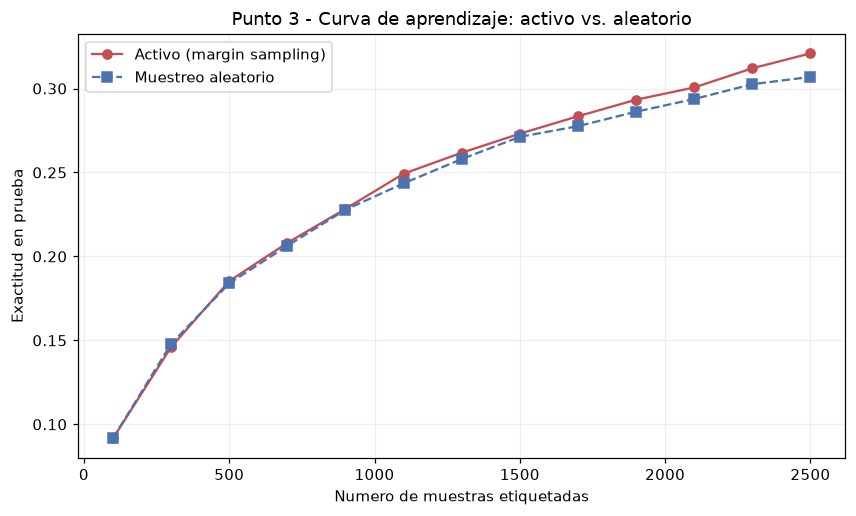

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(n_etiquetas, hist_activo, "o-", label="Activo (margin sampling)", color="#c44e52")
ax.plot(n_etiquetas, hist_aleatorio, "s--", label="Muestreo aleatorio", color="#4c72b0")
ax.set_xlabel("Numero de muestras etiquetadas")
ax.set_ylabel("Exactitud en prueba")
ax.set_title("Curva de aprendizaje: activo vs. aleatorio")
ax.legend()
guardar_fig("p3_03_aprendizaje_activo")
plt.show()

Figura guardada en: /home/zahir/IA1/Unsupervised/lab/figs/p3_04_pca.png


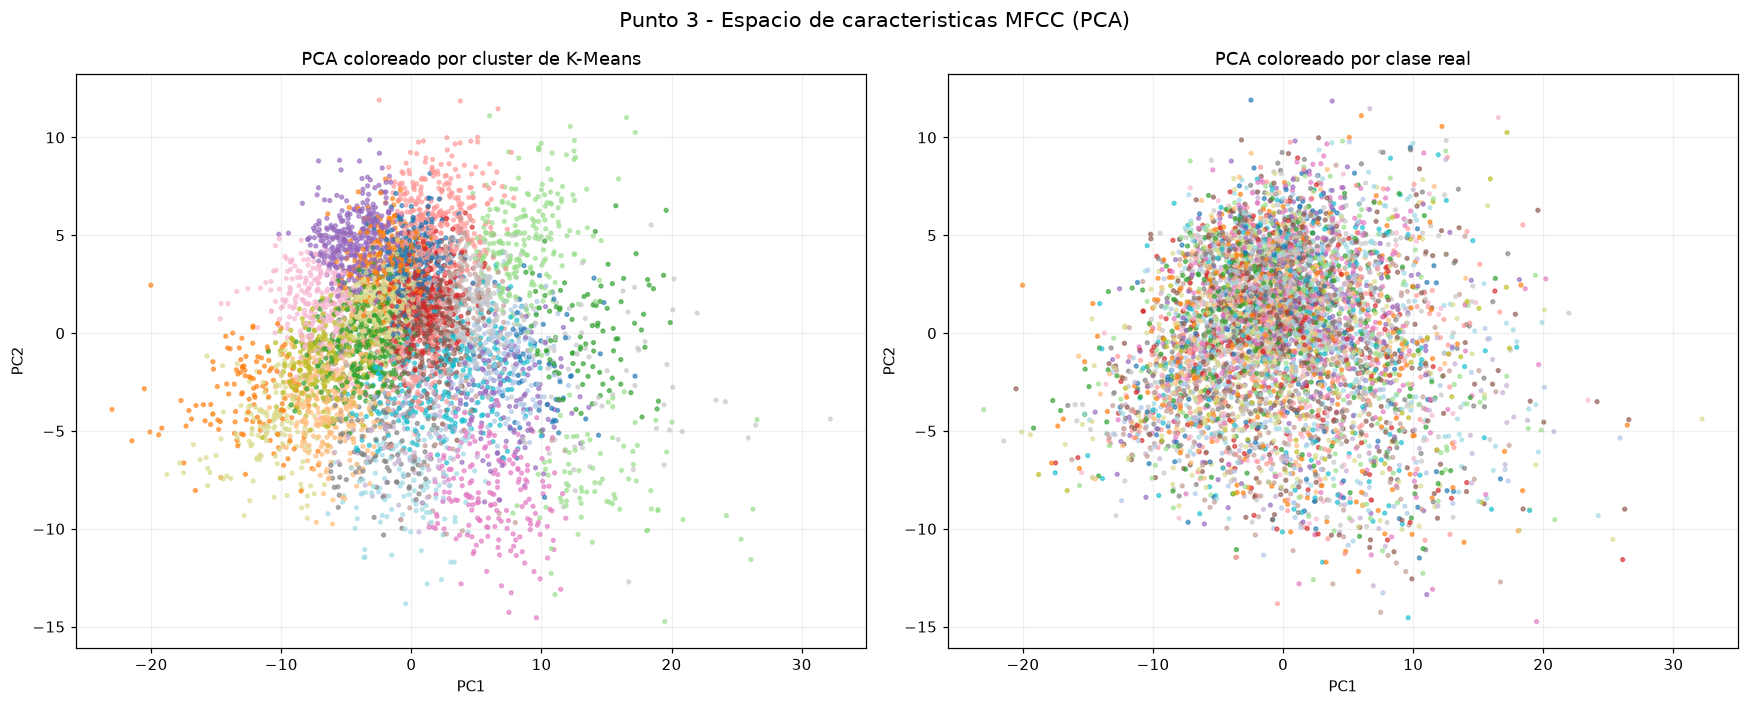

In [24]:
rng_vis = np.random.default_rng(7)
sub = rng_vis.choice(len(X_pool_esc), size=min(6000, len(X_pool_esc)), replace=False)
pca = PCA(n_components=2, random_state=SEMILLA)
Z = pca.fit_transform(X_pool_esc[sub])

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
axes[0].scatter(Z[:, 0], Z[:, 1], c=lab_kmeans[sub], cmap="tab20", s=6, alpha=0.6)
axes[0].set_title("PCA coloreado por cluster de K-Means")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

categorias = {c: i for i, c in enumerate(clases)}
colores = np.array([categorias[c] for c in y_pool[sub]])
axes[1].scatter(Z[:, 0], Z[:, 1], c=colores, cmap="tab20", s=6, alpha=0.6)
axes[1].set_title("PCA coloreado por clase real")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.suptitle("Espacio de caracteristicas MFCC (PCA)", fontsize=14)
plt.tight_layout()
guardar_fig("p3_04_pca")
plt.show()

Figura guardada en: /home/zahir/IA1/Unsupervised/lab/figs/p3_05_matriz_confusion.png


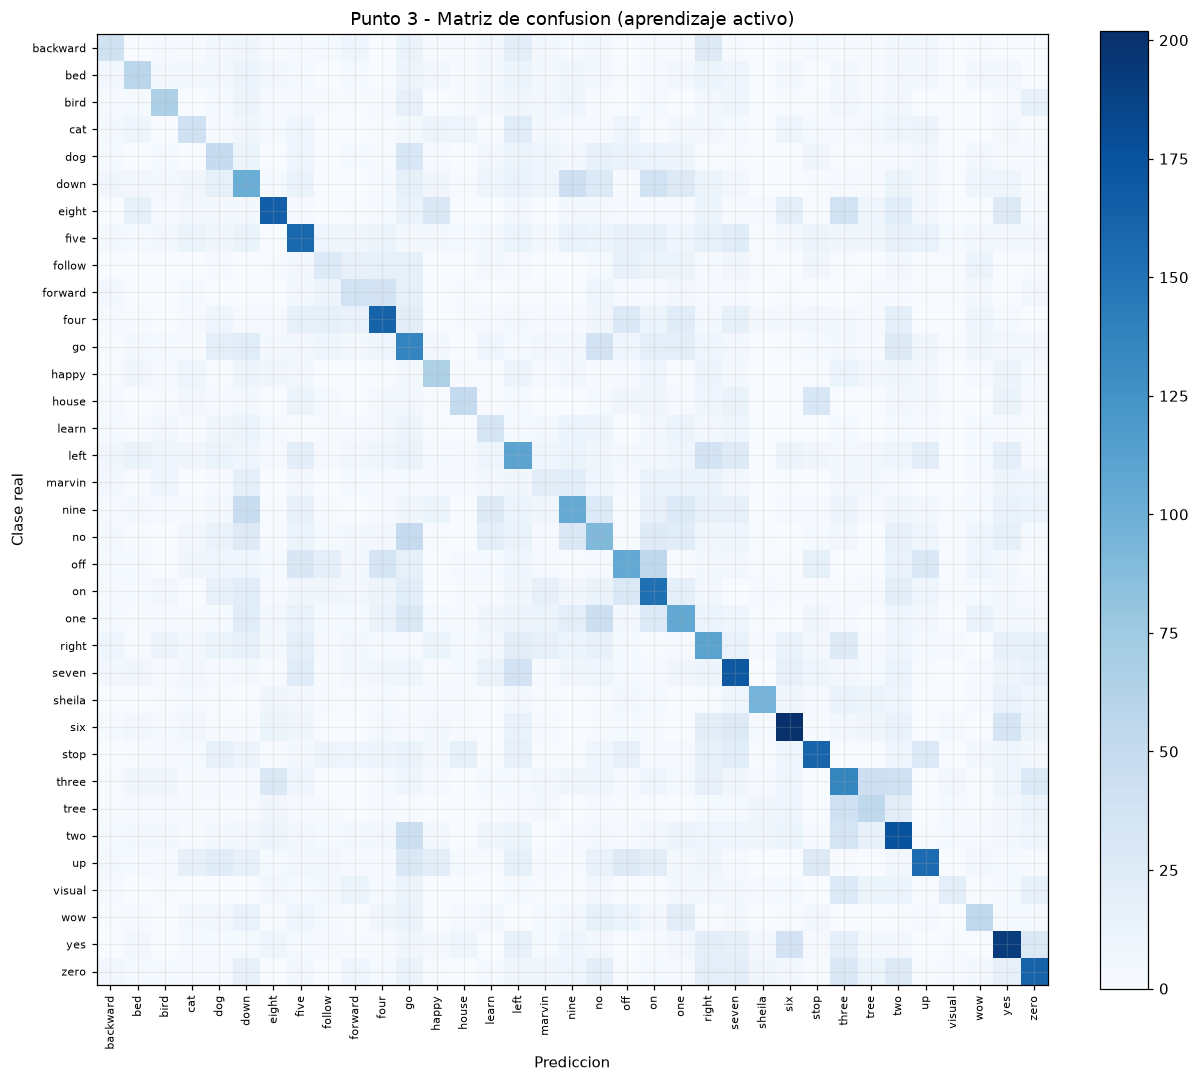

Exactitud del modelo de aprendizaje activo: 0.3248


In [25]:
y_pred_test = clf_activo.predict(X_test_esc)
cm = confusion_matrix(y_test_, y_pred_test, labels=clases)
fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(clases)))
ax.set_yticks(range(len(clases)))
ax.set_xticklabels(clases, rotation=90, fontsize=7)
ax.set_yticklabels(clases, fontsize=7)
ax.set_xlabel("Prediccion")
ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusion (aprendizaje activo)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
guardar_fig("p3_05_matriz_confusion")
plt.show()

print(f"Exactitud del modelo de aprendizaje activo: {clf_activo.score(X_test_esc, y_test_):.4f}")

## 3.8 Estudio de hiperparámetros

Tabla resumida de hiperparametros (hiper_resultados.csv)

[Caracteristicas]
valor  metrica  resultado  extra
   13    techo   0.565198   78.0
   13 acc_1000   0.314403   78.0
   20    techo   0.580554  120.0
   20 acc_1000   0.275965  120.0
   40    techo   0.582372  240.0
   40 acc_1000   0.228896  240.0
   60    techo   0.579373  360.0
   60 acc_1000   0.207269  360.0

[mels]
valor metrica  resultado  extra
   40   techo   0.583099  240.0
   64   techo   0.582372  240.0
  128   techo   0.588642  240.0

[variantes]
     valor metrica  resultado  extra
sin_deltas   techo   0.424716   80.0

[Clasificador C]
valor metrica  resultado  extra
0.001   techo   0.526942    NaN
 0.01   techo   0.566197    NaN
  0.1   techo   0.583008    NaN
  1.0   techo   0.582372    NaN
 10.0   techo   0.582190    NaN
100.0   techo   0.582553    NaN

[max_iter]
valor metrica  resultado  extra
  200   techo   0.583008    NaN
  500   techo   0.582372    NaN
 1000   techo   0.582372    NaN

[escalado]
       val

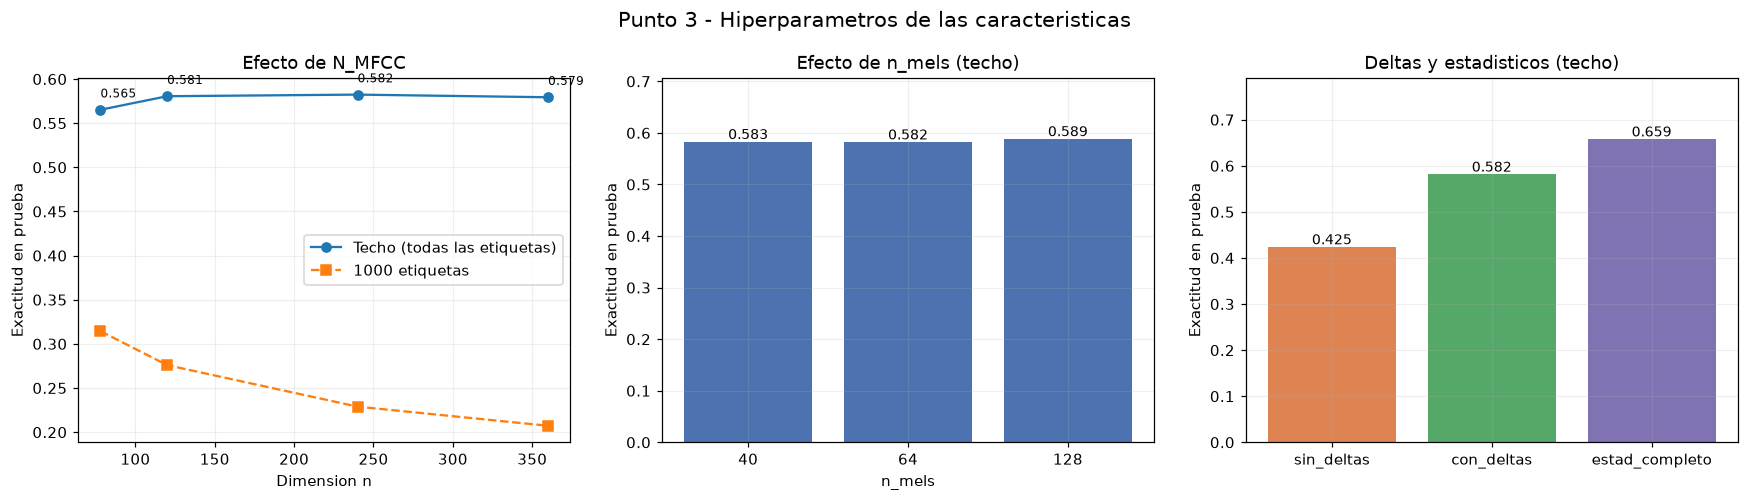

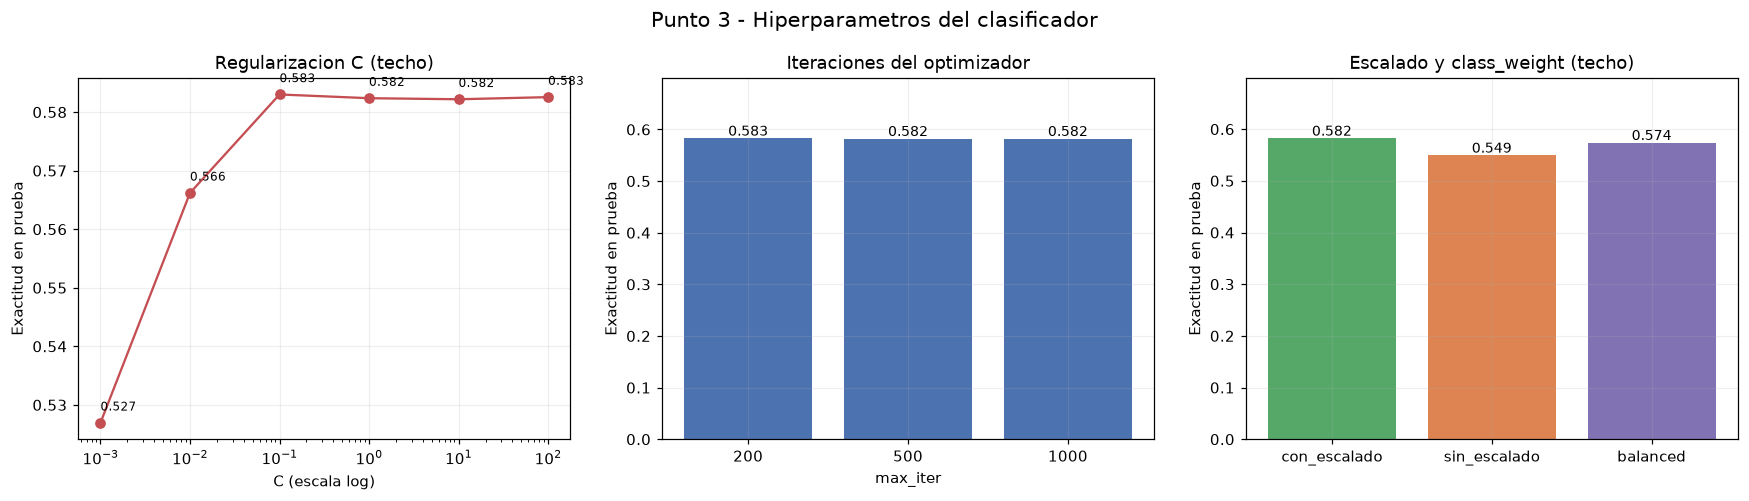

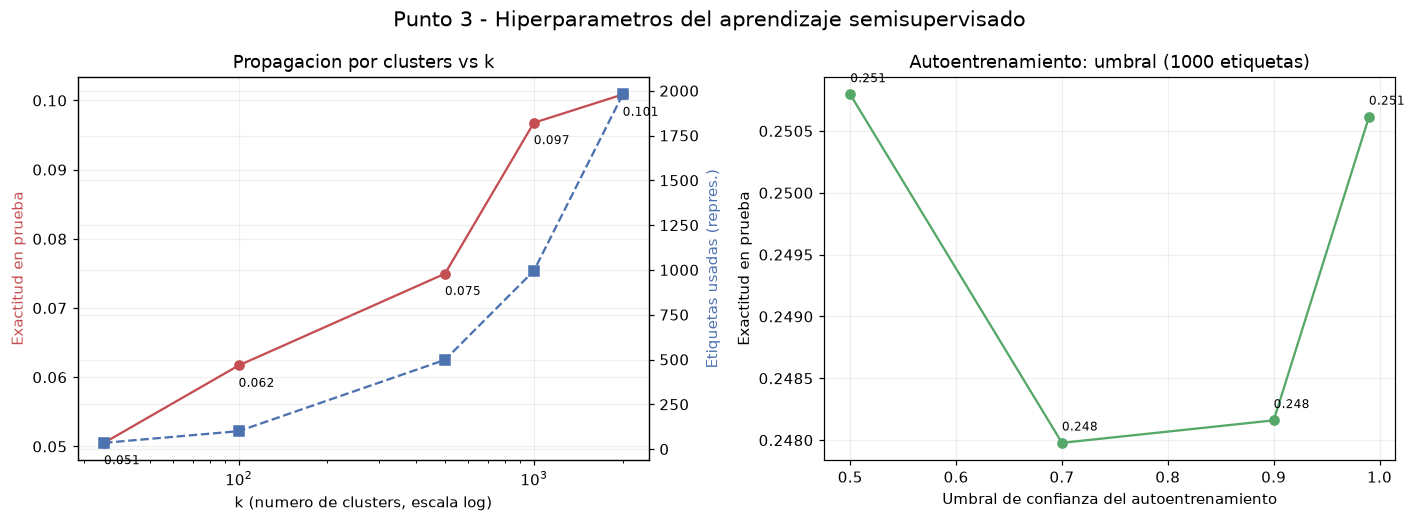

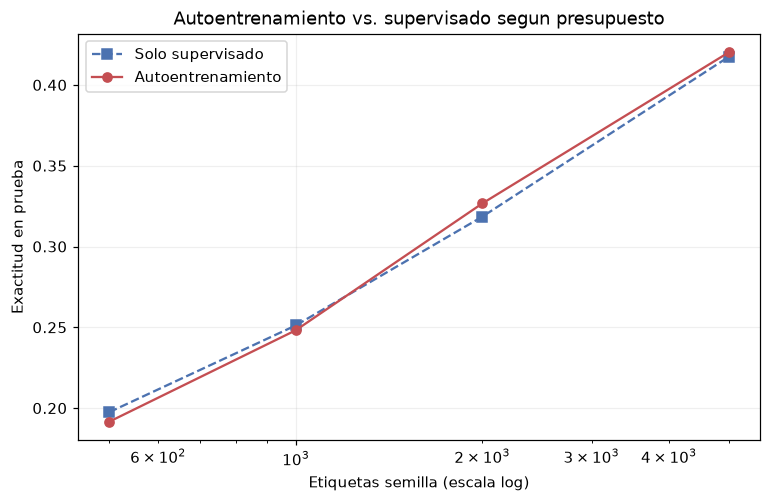

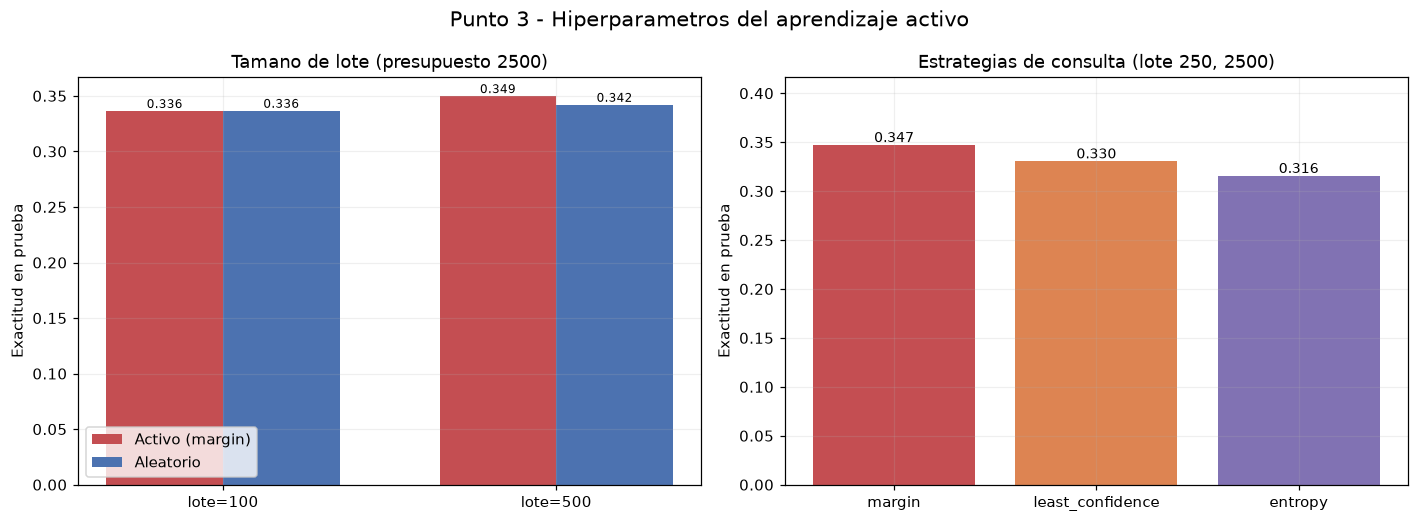

In [26]:
try:
    from IPython.display import Image as Img, display
except Exception:
    Img, display = None, None

df_hp = None
fichero_csv = RAIZ / "hiper_resultados.csv"
if fichero_csv.exists():
    df_hp = pd.read_csv(fichero_csv)
    print("Tabla resumida de hiperparametros (hiper_resultados.csv)")
    for nombre, bloque, parametro in [
        ("Caracteristicas", "E1_features", "n_mfcc"),
        ("mels", "E1_features", "n_mels"),
        ("variantes", "E1_features", "sin_deltas"),
        ("Clasificador C", "E2_clasificador", "C"),
        ("max_iter", "E2_clasificador", "max_iter"),
        ("escalado", "E2_clasificador", "con_escalado"),
        ("KMeans k", "E3_semi", "kmeans_k"),
        ("Umbral auto", "E3_semi", "self_threshold"),
        ("Semilla auto", "E3_semi", "self_nseed"),
        ("Lote activo", "E4_activo", "lote"),
        ("Estrategia", "E4_activo", "estrategia"),
    ]:
        sel = df_hp[(df_hp.bloque == bloque) & (df_hp.parametro == parametro)]
        if sel.empty:
            continue
        print(f"\n[{nombre}]")
        print(sel[["valor", "metrica", "resultado", "extra"]].to_string(index=False))

if Img is not None:
    for f in ["p3_hp_01_features", "p3_hp_02_clasificador",
              "p3_hp_03_semisupervisado", "p3_hp_04_autotrain_semilla",
              "p3_hp_05_activo"]:
        ruta = DIR_FIGS / f"{f}.png"
        if ruta.exists():
            display(Img(filename=str(ruta), width=880))

**Hallazgos del estudio.**

- *Características:* `N_MFCC = 40` es suficiente (más coeficientes no ayudan),
  `n_mels = 128` mejora ligeramente y, sobre todo, añadir **cuantiles** (p10 y
  p90) a la media y desviación estándar sube el **techo de 0.583 a 0.659**.
- *Clasificador:* `C = 0.1` es el mejor (con C muy pequeño la exactitud cae);
  `max_iter` no influye; el **escalado** es imprescindible.
- *Semisupervisado:* la propagación por clusters mejora al aumentar `k` pero
  sigue muy por debajo del supervisado con el mismo número de etiquetas; el
  autoentrenamiento solo aporta cuando la semilla es mayor (~2000 etiquetas).
- *Activo:* **margin** es la mejor estrategia (supera a least-confidence y a
  entropía) y un **lote mayor** (500) aprovecha mejor el presupuesto.

## Configuración optimizada vs. baseline

Con los mejores hiperparámetros encontrados se compara el resultado del Punto 3
frente a la configuración base usada en celdas anteriores. Los valores optimizados se
recuperan de `hiper_resultados.csv` (generado por `hiperparametros.ipynb`).

                        metrica  baseline  optimizado
 Techo (todas las 94.824 etiq.)  0.583008    0.658701
       Activo a 2.500 etiquetas  0.320915    0.349478
    Aleatorio a 2.500 etiquetas  0.306891    0.341617
   Ventaja activo vs. aleatorio  0.014024    0.007860
Autoentrenamiento a 2.000 etiq.  0.318492    0.326670

Mejores hiperparametros encontrados: {'best_n_mfcc': 40, 'best_C': 0.1, 'best_self_threshold': 0.5, 'best_lote': 500, 'best_estrategia': 'margin', 'techo': 0.5830077237619264, 'acc_activa': 0.3494775102226261}


Figura guardada en: /home/zahir/IA1/Unsupervised/lab/figs/p3_06_resumen_optimizado.png


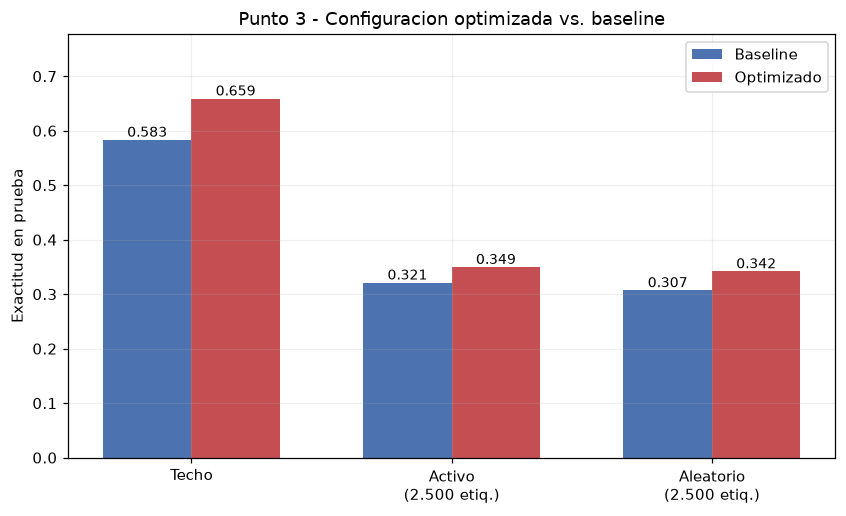

In [27]:
def fila_hp(bloque, parametro, valor, metrica):
    if df_hp is None:
        return np.nan
    sel = df_hp[(df_hp.bloque == bloque) & (df_hp.parametro == parametro)
                & (df_hp.metrica == metrica)]
    if valor is not None:
        sel = sel[sel.valor.astype(str) == str(valor)]
    return float(sel.resultado.iloc[0]) if len(sel) else np.nan


techo_opt = fila_hp("E1_features", "estad_completo", "estad_completo", "techo")
act_opt = fila_hp("E4_activo", "lote", 500, "activo")
ale_opt = fila_hp("E4_activo", "lote", 500, "aleatorio")
auto_2000_solo = fila_hp("E3_semi", "self_nseed", 2000, "solo_supervisado")
auto_2000_auto = fila_hp("E3_semi", "self_nseed", 2000, "autotraining")

mejores_hp = {}
fichero_json = RAIZ / "hiper_resumen.json"
if fichero_json.exists():
    import json as _json
    mejores_hp = _json.load(open(fichero_json))

tabla_hp = pd.DataFrame({
    "metrica": ["Techo (todas las 94.824 etiq.)", "Activo a 2.500 etiquetas",
                "Aleatorio a 2.500 etiquetas", "Ventaja activo vs. aleatorio",
                "Autoentrenamiento a 2.000 etiq."],
    "baseline": [acc_oraculo, hist_activo[-1], hist_aleatorio[-1],
                 hist_activo[-1] - hist_aleatorio[-1], auto_2000_solo],
    "optimizado": [techo_opt, act_opt, ale_opt, act_opt - ale_opt, auto_2000_auto],
})
print(tabla_hp.to_string(index=False))
if mejores_hp:
    print("\nMejores hiperparametros encontrados:", mejores_hp)

fig, ax = plt.subplots(figsize=(9, 5))
grupos = ["Techo", "Activo\n(2.500 etiq.)", "Aleatorio\n(2.500 etiq.)"]
base = [acc_oraculo, hist_activo[-1], hist_aleatorio[-1]]
opt = [techo_opt, act_opt, ale_opt]
x = np.arange(len(grupos))
ancho = 0.34
b1 = ax.bar(x - ancho / 2, base, ancho, label="Baseline", color="#4c72b0")
b2 = ax.bar(x + ancho / 2, opt, ancho, label="Optimizado", color="#c44e52")
for bars in (b1, b2):
    for br in bars:
        ax.text(br.get_x() + br.get_width() / 2, br.get_height() + 0.006,
                f"{br.get_height():.3f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(grupos)
ax.set_ylabel("Exactitud en prueba")
ax.set_ylim(0, max(max(base), max(opt)) * 1.18)
ax.set_title("Punto 3 - Configuracion optimizada vs. baseline")
ax.legend()
guardar_fig("p3_06_resumen_optimizado")
plt.show()

**Interpretación y motivo por el que no conviene seguir afinando.**

La ganancia de los hiperparámetros es real pero **decreciente**: C pasa de 0.583
a 0.583 (sin cambio), `N_MFCC` no mejora más allá de 40 y la mayor mejora
proviene de enriquecer la representación (cuantiles), no de "afinar" los
clasificadores. Con eso el techo pasa de 0.583 a 0.659 y el aprendizaje activo
de 0.321 a 0.349. Más allá de esto, el límite lo impone la **representación**
(estadísticos globales de MFCC): seguir barriendo `C`, `k`, umbrales o lotes
aporta menos de un punto porcentual. Para avanzar haría falta cambiar el modelo
de representación (espectrogramas completos o redes profundas), que está fuera
del alcance de las técnicas vistas en el curso.